B = 2.592000
linear theory, tauI = 10 ms
wEE = 4.166667  pE = 0.034027  pI = -1.549306
omega = 0.499199 rad/ms  period = 12.5865 ms  freq = 79.450 Hz
tauI_min = 0.38580 ms
tauI for 40 Hz: [40.64557983  0.38949955]
linear lag = 78.672 deg

(d)(i)  tauI = 10 ms
eps      period   freq     amp      lag
0.005     12.6990   78.747  0.01973   73.553
0.01      12.8113   78.056  0.02788   71.397
0.02      13.0355   76.713  0.03939   68.357
0.05      13.7062   72.960  0.06207   62.519
0.1       14.8221   67.467  0.08739   56.548
0.2       17.0834   58.536  0.12315   49.743
log-log slope, all eps     = 0.4964
log-log slope, eps <= 0.05 = 0.4978

(d)(ii)  eps = 0.02
tauI     f_sim    f_lin    diff %   lag_sim  lag_lin
2         157.056  162.774   -3.513   59.096   63.947
3         133.397  138.097   -3.404   63.112   68.985
5         106.356  110.082   -3.385   66.258   73.872
7.5        88.015   91.125   -3.414   67.711   76.891
10         76.713   79.450   -3.445   68.357   78.672
15         63.

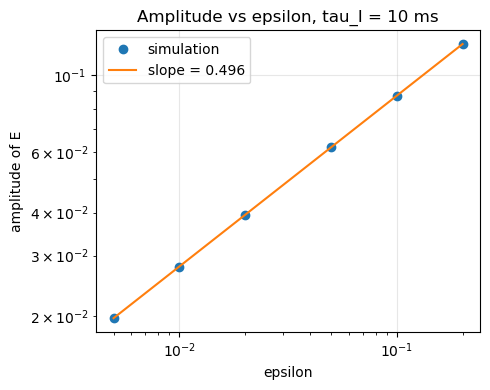

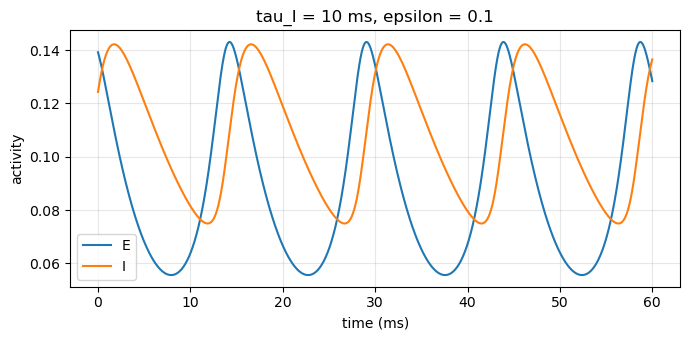

In [8]:
# APPM 4370/5370 HW5, Problem 1: Wilson-Cowan E-I oscillator near a Hopf bifurcation.
%matplotlib inline

import numpy as np
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

# Parameters
eta, tauE, wEI, wIE, Ebar, Ibar = 4.0, 5.0, 10.0, 10.0, 0.1, 0.1
fp = eta * Ebar * (1 - Ebar)          # f' at the fixed point
B = eta**2 * wEI * wIE * Ebar * (1 - Ebar) * Ibar * (1 - Ibar) / tauE

f = lambda x: 1.0 / (1.0 + np.exp(-eta * x))
logit = lambda x: np.log(x / (1 - x)) / eta          # f^{-1}


def params(tauI, eps):
    wHopf = (1 + tauE / tauI) / fp
    wEE = (1 + eps) * wHopf
    pE = logit(Ebar) - wEE * Ebar + wEI * Ibar
    pI = logit(Ibar) - wIE * Ebar
    return wEE, pE, pI


def rhs_factory(tauI, wEE, pE, pI):
    def rhs(t, y):
        E, I = y
        return [(-E + f(wEE * E - wEI * I + pE)) / tauE,
                (-I + f(wIE * E + pI)) / tauI]
    return rhs


def refine(t, y, idx):
    out = []
    for i in idx:
        y0, y1, y2 = y[i - 1], y[i], y[i + 1]
        d = y0 - 2 * y1 + y2
        out.append(t[i] + (0.5 * (y0 - y2) / d if d != 0 else 0.0) * (t[1] - t[0]))
    return np.array(out)


def simulate(tauI, eps, traj=False):
    wEE, pE, pI = params(tauI, eps)
    rhs = rhs_factory(tauI, wEE, pE, pI)

    # settle on the attractor, then measure
    sigma = eps * (1 + tauE / tauI) / (2 * tauE)        # linear growth rate
    Tsettle = max(3000.0, 45.0 / sigma)
    s1 = solve_ivp(rhs, [0, Tsettle], [Ebar + 1e-4, Ibar],
                   method="DOP853", rtol=1e-11, atol=1e-13)

    Tmeas, dt = 600.0, 0.005
    t = np.arange(0, Tmeas, dt)
    s2 = solve_ivp(rhs, [0, Tmeas], s1.y[:, -1], method="DOP853", t_eval=t,
                   rtol=1e-11, atol=1e-13)
    E, I = s2.y

    tE = refine(t, E, find_peaks(E, prominence=1e-6)[0])
    tI = refine(t, I, find_peaks(I, prominence=1e-6)[0])
    period = np.mean(np.diff(tE))

    lags = [tI[tI > te][0] - te for te in tE[:-1] if np.any(tI > te)]
    lag = 360.0 * np.mean(lags) / period
    amp = E.max() - E.min()

    return (period, amp, lag, (t, E, I)) if traj else (period, amp, lag)


# linear theory at tauI = 10 ms (parts a-c)
print(f"B = {B:.6f}")
tauI = 10.0
wEE, pE, pI = params(tauI, 0.0)
w = np.sqrt(B / tauI - 1 / tauI**2)
print("linear theory, tauI = 10 ms")
print(f"wEE = {wEE:.6f}  pE = {pE:.6f}  pI = {pI:.6f}")
print(f"omega = {w:.6f} rad/ms  period = {2*np.pi/w:.4f} ms  freq = {1000*w/(2*np.pi):.3f} Hz")
print(f"tauI_min = {1/B:.5f} ms")
print(f"tauI for 40 Hz: {np.roots([(2*np.pi*0.040)**2, -B, 1.0])}")
print(f"linear lag = {np.degrees(np.arctan(w*tauI)):.3f} deg")

#(d)(i): amplitude vs epsilon
eps = np.array([0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
amps = []
print("\n(d)(i)  tauI = 10 ms")
print("eps      period   freq     amp      lag")
for e in eps:
    P, A, L = simulate(10.0, e)
    amps.append(A)
    print(f"{e:<8} {P:8.4f} {1000/P:8.3f} {A:8.5f} {L:8.3f}")
amps = np.array(amps)

slope, icpt = np.polyfit(np.log(eps), np.log(amps), 1)
slope2 = np.polyfit(np.log(eps[:4]), np.log(amps[:4]), 1)[0]
print(f"log-log slope, all eps     = {slope:.4f}")
print(f"log-log slope, eps <= 0.05 = {slope2:.4f}")

# figure 1 of 2: (d)(i)
fig1, ax1 = plt.subplots(figsize=(5, 4))
ax1.loglog(eps, amps, "o", label="simulation")
ax1.loglog(eps, np.exp(icpt) * eps**slope, "-", label=f"slope = {slope:.3f}")
ax1.set_xlabel("epsilon")
ax1.set_ylabel("amplitude of E")
ax1.set_title("Amplitude vs epsilon, tau_I = 10 ms")
ax1.legend()
ax1.grid(alpha=0.3)
fig1.tight_layout()

# (d)(ii): frequency and lag vs tauI at eps = 0.02
print("\n(d)(ii)  eps = 0.02")
print("tauI     f_sim    f_lin    diff %   lag_sim  lag_lin")
for tI in [2, 3, 5, 7.5, 10, 15, 20]:
    P, A, L = simulate(float(tI), 0.02)
    wl = np.sqrt(B / tI - 1 / tI**2)
    fl = 1000 * wl / (2 * np.pi)
    print(f"{tI:<8} {1000/P:8.3f} {fl:8.3f} {100*(1000/P - fl)/fl:8.3f} "
          f"{L:8.3f} {np.degrees(np.arctan(wl*tI)):8.3f}")

# (d)(iii): limit-cycle time series
P, A, L, (t, E, I) = simulate(10.0, 0.1, traj=True)
m = t < 60

fig2, ax2 = plt.subplots(figsize=(7, 3.5))
ax2.plot(t[m], E[m], label="E")
ax2.plot(t[m], I[m], label="I")
ax2.set_xlabel("time (ms)")
ax2.set_ylabel("activity")
ax2.set_title("tau_I = 10 ms, epsilon = 0.1")
ax2.legend()
ax2.grid(alpha=0.3)
fig2.tight_layout()

# shown once, at the end: exactly two figures, no duplicates
plt.show()
